# G1.2 · Floating point, mixed precision and training-memory math

**ID:** G1.2 · **Target:** 120 min · **Plan week:** 15 (sections 1-3 also fit week 3, "AMP + grad accumulation") · **Part:** G1

**The lab.** Where do the bytes go when you train a transformer, and how few bits can each number use? You
will (1) derive every float format from its bit layout and check against `torch.finfo`; (2) watch fp16
gradients underflow and fix it with loss scaling; (3) pin down what `torch.autocast` actually runs in low
precision; (4) predict, then **measure**, the memory of a `tinygpt` training step: weights, gradients, Adam
states, activations (per tensor, per layer, per model), and what activation checkpointing buys and costs;
(5) estimate the memory to train a 7B model (guide mock checklist: *"Estimate memory and FLOPs for training a 7B
model on N tokens"*; the FLOPs half is G1.3).

Guide G1 "Must include": *Memory math: params + grads + optimizer states + activations; activation
checkpointing; mixed precision (bf16/fp8).* The RTX 3090 has no FP8 tensor cores, so FP8 is format-only here.

Fill in every `raise NotImplementedError`; predict each number before you run the cell that measures it.
Solution runtime: about 1 min on an RTX 3090.

## Sources
- P. Micikevicius et al., *Mixed Precision Training*, ICLR 2018, arXiv:1710.03740 (fp32 master weights, loss
  scaling, Fig. 3 gradient histogram) — https://arxiv.org/abs/1710.03740
- D. Kalamkar et al., *A Study of BFLOAT16 for Deep Learning Training*, 2019, arXiv:1905.12322 — https://arxiv.org/abs/1905.12322
- P. Micikevicius et al., *FP8 Formats for Deep Learning*, 2022, arXiv:2209.05433 (E4M3 max 448 with no
  infinities; E5M2 IEEE-like, max 57344; Table 1) — https://arxiv.org/abs/2209.05433
- S. Rajbhandari et al., *ZeRO: Memory Optimizations Toward Training Trillion Parameter Models*, SC 2020,
  arXiv:1910.02054 (§3.1: mixed-precision Adam needs $2\Psi + 2\Psi + 12\Psi = 16\Psi$ bytes) — https://arxiv.org/abs/1910.02054
- V. Korthikanti et al., *Reducing Activation Recomputation in Large Transformer Models*, MLSys 2023,
  arXiv:2205.05198 (§4.1, Eq. 1: $sbh(34 + 5as/h)$ bytes per layer) — https://arxiv.org/abs/2205.05198
- T. Chen, B. Xu, C. Zhang, C. Guestrin, *Training Deep Nets with Sublinear Memory Cost*, 2016,
  arXiv:1604.06174 ($O(\sqrt N)$ checkpointing) — https://arxiv.org/abs/1604.06174
- Q. Anthony, S. Biderman, H. Schoelkopf, *Transformer Math 101*, EleutherAI blog, 2023 — https://blog.eleuther.ai/transformer-math/
- N. Tazi et al., *The Ultra-Scale Playbook: Training LLMs on GPU Clusters*, Hugging Face, 2025 (memory
  anatomy, activation recomputation) — https://huggingface.co/spaces/nanotron/ultrascale-playbook
- Stanford CS336 Spring 2026, Assignment 2 handout §2.1.5 (mixed-precision accumulation demo, ToyModel autocast
  dtypes), §2.1.6 (memory snapshots), §3 (saved-tensor hooks, `torch.utils.checkpoint`) —
  https://github.com/stanford-cs336/assignment2-systems @ca8bc81 (MIT). The accumulation loop and ToyModel are
  adapted from the handout; the prose and the tinygpt measurements are ours.
- PyTorch docs: AMP / autocast op lists https://docs.pytorch.org/docs/stable/amp.html ; `torch.amp.GradScaler`
  (same page); CUDA memory snapshots https://docs.pytorch.org/docs/stable/torch_cuda_memory.html (viewer:
  https://pytorch.org/memory_viz); `torch.utils.checkpoint` https://docs.pytorch.org/docs/stable/checkpoint.html ;
  saved-tensor hooks https://docs.pytorch.org/docs/stable/autograd.html#saved-tensors-default-hooks
- IEEE 754-2019, *Standard for Floating-Point Arithmetic*, DOI: 10.1109/IEEESTD.2019.8766229
- NVIDIA GA102 whitepaper v2, p. 26 (TF32 = 8-bit exponent, 10-bit mantissa; BF16 = 8/7) —
  https://www.nvidia.com/content/PDF/nvidia-ampere-ga-102-gpu-architecture-whitepaper-v2.pdf

In [1]:
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint

from prep import Session, check, check_close, seed_everything
from prep.tinygpt import GPT, GPTConfig, num_params, random_batch

s = Session("G1.2", target_min=120)
seed_everything(0)
dev = torch.device("cuda")
torch.backends.cuda.matmul.fp32_precision = "ieee"  # true FP32 unless a cell says otherwise

[G1.2] started 16:49; target 120 min


## 1. Float formats from their bits

A binary float with $e$ exponent bits and $m$ mantissa bits stores (sign $S$, exponent field $E$, fraction $F$).
With bias $b = 2^{e-1}-1$:
- **normal** ($0 < E < 2^e-1$): $(-1)^S\,(1 + F/2^m)\,2^{E-b}$
- **subnormal** ($E = 0$): $(-1)^S\,(F/2^m)\,2^{1-b}$ (gradual underflow down to $2^{1-b-m}$)
- **IEEE special** ($E = 2^e-1$): $F=0$ is $\pm\infty$, otherwise NaN.

So: machine epsilon (gap above 1.0) $= 2^{-m}$; smallest normal $= 2^{1-b}$; smallest subnormal $= 2^{1-b-m}$;
largest finite $= (2-2^{-m})\,2^{2^e-2-b}$. Exponent bits buy **range**, mantissa bits buy **precision**.

| format | e | m | where it shows up |
| --- | --- | --- | --- |
| fp32 | 8 | 23 | master weights, optimizer states, reductions |
| tf32 | 8 | 10 | tensor-core input format for FP32 matmuls on Ampere+ (19 bits used, stored as fp32) |
| fp16 | 5 | 10 | Volta-era mixed precision; needs loss scaling |
| bf16 | 8 | 7 | fp32 range with 8 bits of precision; no loss scaling needed (Kalamkar et al. 2019) |
| fp8 E4M3 ("fn") | 4 | 3 | Hopper/Ada fwd activations+weights; *no infinities*, only S.1111.111 is NaN, so max = 448 |
| fp8 E5M2 | 5 | 2 | gradients; IEEE-like, max 57344 (Micikevicius et al. 2022, Table 1) |

**Exercise 1.1.** `float_params(e, m, ieee_specials=True)` returns `max`, `min_normal`, `min_subnormal`, `eps`.
With `ieee_specials=False` (E4M3fn), the all-ones exponent holds normal numbers too, except the all-ones
mantissa (NaN), so the largest finite has exponent field $2^e-1$ and mantissa $1.11\dots10_2$.

In [2]:
def float_params(e, m, ieee_specials=True):
    bias = 2 ** (e - 1) - 1
    if ieee_specials:
        mx = (2 - 2.0**-m) * 2.0 ** (2**e - 2 - bias)
    else:  # E4M3fn: exponent field 2^e-1 is usable; mantissa all-ones is NaN
        mx = (2 - 2.0 ** (1 - m)) * 2.0 ** (2**e - 1 - bias)
    return dict(max=mx, min_normal=2.0 ** (1 - bias), min_subnormal=2.0 ** (1 - bias - m), eps=2.0**-m)


fmts = {torch.float32: (8, 23, True), torch.float16: (5, 10, True), torch.bfloat16: (8, 7, True),
        torch.float8_e4m3fn: (4, 3, False), torch.float8_e5m2: (5, 2, True)}
for dt, (e, m, ieee) in fmts.items():
    fi, mine = torch.finfo(dt), float_params(e, m, ieee)
    for k, ref in (("max", fi.max), ("min_normal", fi.smallest_normal), ("eps", fi.eps)):
        check_close(f"{dt} {k}", mine[k], ref, rtol=1e-6, atol=0)
check_close("fp16 min subnormal 2^-24", float_params(5, 10)["min_subnormal"], 2.0**-24, atol=0)
check_close("tf32 eps 2^-10", float_params(8, 10)["eps"], 2.0**-10, atol=0)
print({k: f"{v:.3g}" for k, v in float_params(8, 10).items()}, "<- tf32: fp32 range, fp16 precision")

ok  torch.float32 max
ok  torch.float32 min_normal
ok  torch.float32 eps
ok  torch.float16 max
ok  torch.float16 min_normal
ok  torch.float16 eps
ok  torch.bfloat16 max
ok  torch.bfloat16 min_normal
ok  torch.bfloat16 eps
ok  torch.float8_e4m3fn max
ok  torch.float8_e4m3fn min_normal
ok  torch.float8_e4m3fn eps
ok  torch.float8_e5m2 max
ok  torch.float8_e5m2 min_normal
ok  torch.float8_e5m2 eps
ok  fp16 min subnormal 2^-24
ok  tf32 eps 2^-10
{'max': '3.4e+38', 'min_normal': '1.18e-38', 'min_subnormal': '1.15e-41', 'eps': '0.000977'} <- tf32: fp32 range, fp16 precision


**Exercise 1.2.** `decode_bits(bits, e, m)`: the value of an IEEE-style bit pattern (an int with $1+e+m$
bits, sign first) as a Python float, covering normal, subnormal, zero, inf, NaN. The check decodes *every*
fp16 and bf16 bit pattern and every fp8 E5M2 pattern, and compares with PyTorch reinterpreting the same bits.

In [3]:
def decode_bits(bits, e, m):
    sign = -1.0 if (bits >> (e + m)) & 1 else 1.0
    E, Fr = (bits >> m) & ((1 << e) - 1), bits & ((1 << m) - 1)
    bias = 2 ** (e - 1) - 1
    if E == (1 << e) - 1:
        return sign * math.inf if Fr == 0 else math.nan
    if E == 0:
        return sign * (Fr / 2**m) * 2.0 ** (1 - bias)
    return sign * (1 + Fr / 2**m) * 2.0 ** (E - bias)


def check_all_patterns(dt, int_dt, n_bits, e, m):
    pats = torch.arange(2**n_bits, dtype=torch.int64)
    ref = pats.to(int_dt).view(dt).double().numpy() if n_bits == 8 else \
        (pats - (pats >= 2 ** (n_bits - 1)) * 2**n_bits).to(int_dt).view(dt).double().numpy()
    got = np.array([decode_bits(int(b), e, m) for b in pats])
    ok = np.array_equal(np.isnan(got), np.isnan(ref)) and np.array_equal(got[~np.isnan(got)], ref[~np.isnan(ref)])
    check(f"all {2**n_bits} {dt} bit patterns decode exactly", ok)


check_all_patterns(torch.float16, torch.int16, 16, 5, 10)
check_all_patterns(torch.bfloat16, torch.int16, 16, 8, 7)
check_all_patterns(torch.float8_e5m2, torch.uint8, 8, 5, 2)

ok  all 65536 torch.float16 bit patterns decode exactly
ok  all 65536 torch.bfloat16 bit patterns decode exactly
ok  all 256 torch.float8_e5m2 bit patterns decode exactly


### Rounding you will meet in practice
Adapted from CS336 A2 §2.1.5: add 0.01 a thousand times. In fp16, $0.01$ is not representable and once the sum
reaches a few units the gap between neighbouring fp16 numbers ($2^{-8}$ near 4–8) is a sizeable fraction of 0.01,
so the additions round badly. This is why reductions and accumulators stay in fp32 even when inputs are 16-bit.

In [4]:
for acc_dt, add_dt in ((torch.float32, torch.float32), (torch.float16, torch.float16), (torch.float32, torch.float16)):
    acc = torch.tensor(0, dtype=acc_dt)
    for _ in range(1000):
        acc += torch.tensor(0.01, dtype=add_dt)
    print(f"accumulate in {acc_dt}, add {add_dt}: {acc.item():.6f}")
print("fp16: 2048 + 1 =", (torch.tensor(2048.0, dtype=torch.float16) + 1).item(),
      "  bf16: 256 + 1 =", (torch.tensor(256.0, dtype=torch.bfloat16) + 1).item())

# Matmul error vs float64 on this GPU (same inputs, K = 4096).
n = 4096
A64, B64 = torch.randn(n, n, dtype=torch.float64, device=dev), torch.randn(n, n, dtype=torch.float64, device=dev)
ref = A64 @ B64
rel = {}
for name, dt, prec in (("fp32", torch.float32, "ieee"), ("tf32", torch.float32, "tf32"),
                       ("fp16", torch.float16, "ieee"), ("bf16", torch.bfloat16, "ieee")):
    torch.backends.cuda.matmul.fp32_precision = prec
    C = (A64.to(dt) @ B64.to(dt)).double()
    rel[name] = ((C - ref).norm() / ref.norm()).item()
torch.backends.cuda.matmul.fp32_precision = "ieee"
print({k: f"{v:.1e}" for k, v in rel.items()}, "relative Frobenius error vs float64")
check("error ordering fp32 < tf32 ~ fp16 < bf16", rel["fp32"] < rel["tf32"] < rel["bf16"] and rel["fp16"] < rel["bf16"])
del A64, B64, ref, C

accumulate in torch.float32, add torch.float32: 10.000134
accumulate in torch.float16, add torch.float16: 9.953125
accumulate in torch.float32, add torch.float16: 10.002136
fp16: 2048 + 1 = 2048.0   bf16: 256 + 1 = 256.0


{'fp32': '1.1e-06', 'tf32': '2.9e-04', 'fp16': '3.6e-04', 'bf16': '2.9e-03'} relative Frobenius error vs float64
ok  error ordering fp32 < tf32 ~ fp16 < bf16


Notice that tf32 and fp16 land at about the same error (both have 10 mantissa bits) and bf16 about 8× worse
(7 bits). Those errors come from rounding the *inputs*; the products are accumulated in fp32 in all three cases.

## 2. Why fp16 needs loss scaling: gradients underflow

fp16's smallest subnormal is $2^{-24}\approx 6\times10^{-8}$ and its smallest normal $2^{-14}\approx 6\times 10^{-5}$.
Gradients are often far smaller. Micikevicius et al. (Fig. 3) show a histogram of SSD activation gradients where most
non-zero values sit below fp16's range. Our tinygpt makes it concrete: with mean cross-entropy over $BT$ tokens,
$\partial L/\partial z_{t,v} = (p_{t,v} - y_{t,v})/(BT)$. At init $p\approx 1/V$ with $V = 50257$ and $BT = 2048$:
about $10^{-8}$, **below the smallest fp16 subnormal**. Under autocast the head matmul's backward takes that gradient in
fp16, so it flushes to zero.

**Predict:** what fraction of $\partial L/\partial z$ entries become exactly 0 when cast to fp16? With the loss
multiplied by $2^{16}$ first?

In [5]:
cfg = GPTConfig()
xb, yb = random_batch(cfg, 8, dev, torch.Generator(device=dev).manual_seed(0))
torch.manual_seed(0)
model = GPT(cfg).to(dev)
logits = model(xb).detach().requires_grad_()
F.cross_entropy(logits.flatten(0, 1), yb.flatten()).backward()
g = logits.grad
for scale in (1.0, 2.0**16):
    gs16 = (g * scale).half()
    print(f"scale {scale:>8.0f}: |g| median {(g * scale).abs().median().item():.2e}   "
          f"zero in fp16: {(gs16 == 0).float().mean().item():.1%}   subnormal in fp16: "
          f"{((gs16 != 0) & (gs16.abs() < 2**-14)).float().mean().item():.1%}")
check("unscaled dlogits mostly flush to zero in fp16", ((g.half()) == 0).float().mean() > 0.9)
del logits, g

scale        1: |g| median 9.00e-09   zero in fp16: 99.9%   subnormal in fp16: 0.1%
scale    65536: |g| median 5.90e-04   zero in fp16: 0.0%   subnormal in fp16: 0.0%
ok  unscaled dlogits mostly flush to zero in fp16


**Measure the effect on training.** Same init, same fixed batch (the model memorizes it), 40 AdamW steps in fp32,
bf16 autocast, fp16 autocast without scaling, and fp16 autocast with `torch.amp.GradScaler`.

fp32             loss 10.91 -> 1.10   zero gradient entries at step 0: 0.0%


bf16             loss 10.91 -> 1.80   zero gradient entries at step 0: 0.0%


fp16             loss 10.91 -> 0.70   zero gradient entries at step 0: 48.6%


fp16+GradScaler  loss 10.91 -> 1.06   zero gradient entries at step 0: 0.0%


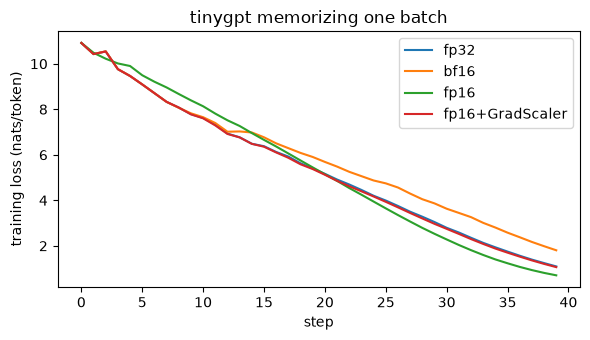

ok  fp16 without scaling zeroes a large share of gradient entries
ok  GradScaler restores (almost) all gradient entries


In [6]:
def train_curve(mode, steps=40):
    torch.manual_seed(0)
    m = GPT(cfg).to(dev)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-3)
    dt = {"fp32": None, "bf16": torch.bfloat16, "fp16": torch.float16, "fp16+GradScaler": torch.float16}[mode]
    scaler = torch.amp.GradScaler("cuda", enabled=mode == "fp16+GradScaler")
    losses, zero_frac = [], None
    for i in range(steps):
        with torch.autocast("cuda", dtype=dt or torch.float32, enabled=dt is not None):
            _, loss = m(xb, yb)
        scaler.scale(loss).backward()
        if i == 0:
            gall = torch.cat([p.grad.flatten() for p in m.parameters()])
            zero_frac = (gall == 0).float().mean().item()
        scaler.step(opt)
        scaler.update()
        opt.zero_grad(set_to_none=True)
        losses.append(loss.item())
    return losses, zero_frac


curves = {}
for mode in ("fp32", "bf16", "fp16", "fp16+GradScaler"):
    curves[mode] = train_curve(mode)
    print(f"{mode:16s} loss {curves[mode][0][0]:.2f} -> {curves[mode][0][-1]:.2f}   "
          f"zero gradient entries at step 0: {curves[mode][1]:.1%}")
plt.figure(figsize=(6, 3.5))
for mode, (l, _) in curves.items():
    plt.plot(l, label=mode)
plt.xlabel("step"); plt.ylabel("training loss (nats/token)"); plt.title("tinygpt memorizing one batch"); plt.legend()
plt.tight_layout(); plt.show()
check("fp16 without scaling zeroes a large share of gradient entries", curves["fp16"][1] > 0.2)
check("GradScaler restores (almost) all gradient entries", curves["fp16+GradScaler"][1] < 0.01)

Read it carefully. Without scaling, about half of all gradient entries are exactly zero: most of the tied
embedding/head matrix, whose gradient for non-target tokens is that $10^{-8}$ term. The loss still falls, because
Adam divides each coordinate by its own RMS and the surviving gradients are fine, but you are now training a
different model: rows for tokens absent from the batch get no "push down" signal at all, which shows up as worse
held-out loss and rare-token behaviour, and with SGD the damage is direct. bf16 has fp32's exponent range, so
nothing underflows. A "the loss went down" check would have missed this bug.

**Loss scaling** (Micikevicius et al. 2018): multiply the loss by $S$ before `backward()` so every gradient is $S$
times larger, unscale in fp32 before the optimizer step. **Dynamic** scaling picks $S$ automatically: if any gradient
is inf/NaN, skip the step and halve $S$; after `growth_interval` consecutive good steps, double $S$.

**Exercise 2.1.** Implement `DynamicLossScaler.update(found_inf)` with exactly `torch.amp.GradScaler`'s rule
(backoff on overflow and reset the counter; grow after `growth_interval` consecutive finite steps). Return
`True` if the optimizer step must be skipped.

In [7]:
class DynamicLossScaler:
    def __init__(self, init_scale=2.0**16, growth_factor=2.0, backoff_factor=0.5, growth_interval=2000):
        self.scale, self.growth, self.backoff, self.interval = init_scale, growth_factor, backoff_factor, growth_interval
        self.good_steps = 0

    def update(self, found_inf: bool) -> bool:
        if found_inf:
            self.scale *= self.backoff
            self.good_steps = 0
            return True
        self.good_steps += 1
        if self.good_steps == self.interval:
            self.scale *= self.growth
            self.good_steps = 0
        return False


p = nn.Parameter(torch.zeros(1, device=dev))
sgd = torch.optim.SGD([p], lr=0.0)
ref_scaler = torch.amp.GradScaler("cuda", init_scale=2.0**10, growth_factor=2.0, backoff_factor=0.5, growth_interval=3)
ref_scaler.scale(torch.ones(1, device=dev))  # GradScaler initializes its state lazily
mine = DynamicLossScaler(init_scale=2.0**10, growth_interval=3)
pattern = [False, False, False, True, False, True, True, False, False, False, False, False, False, True]
for i, inf in enumerate(pattern):
    p.grad = torch.tensor([math.inf if inf else 1.0], device=dev)
    ref_scaler.step(sgd)
    ref_scaler.update()
    skipped = mine.update(inf)
    assert mine.scale == ref_scaler.get_scale(), f"step {i}: scale {mine.scale} != GradScaler {ref_scaler.get_scale()}"
    assert skipped == inf
check("DynamicLossScaler matches torch.amp.GradScaler on an overflow pattern", True)

ok  DynamicLossScaler matches torch.amp.GradScaler on an overflow pattern


## 3. What `torch.autocast` actually does

Autocast does **not** convert your model. Parameters stay fp32. At each op, autocast looks the op up in a list
(PyTorch AMP docs): ops that benefit from tensor cores (`linear`, `matmul`, `conv`, `bmm`, SDPA) cast inputs to the
low-precision dtype; ops that need range or accurate reductions (`layer_norm`, `softmax`, `log_softmax`,
`cross_entropy`, `sum`, `exp`, `pow`…) run in fp32; everything else runs in the widest input dtype. Casts of
weights are cached for the duration of the autocast region. Gradients come back in the parameters' dtype (fp32)
because the backward of the cast op casts them back.

**Exercise 3.1** (CS336 A2 §2.1.5(a), adapted). Fill in `predicted` with the dtype you expect for each tensor in
the `ToyModel` below under fp16 autocast, *then* run the check.

In [8]:
class ToyModel(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__()
        self.fc1 = nn.Linear(d_in, 10, bias=False)
        self.ln = nn.LayerNorm(10)
        self.fc2 = nn.Linear(10, d_out, bias=False)

    def forward(self, x):
        h1 = F.relu(self.fc1(x))
        h2 = self.ln(h1)
        return self.fc2(h2), h1, h2


toy = ToyModel(20, 5).to(dev)
with torch.autocast("cuda", dtype=torch.float16):
    out, h1, h2 = toy(torch.randn(8, 20, device=dev))
    loss = F.cross_entropy(out, torch.zeros(8, dtype=torch.long, device=dev))
loss.backward()
measured = {"param in autocast": toy.fc1.weight.dtype, "fc1 output": h1.dtype, "layernorm output": h2.dtype,
            "logits": out.dtype, "loss": loss.dtype, "grad": toy.fc1.weight.grad.dtype}
predicted = {"param in autocast": torch.float32, "fc1 output": torch.float16, "layernorm output": torch.float32,
             "logits": torch.float16, "loss": torch.float32, "grad": torch.float32}
for k in measured:
    check(f"autocast dtype of {k}", predicted[k] == measured[k], f"predicted {predicted[k]}, measured {measured[k]}")

ok  autocast dtype of param in autocast
ok  autocast dtype of fc1 output
ok  autocast dtype of layernorm output
ok  autocast dtype of logits
ok  autocast dtype of loss
ok  autocast dtype of grad


**bf16 vs fp16 on this GPU.** Same tensor-core rate (71 TFLOPS with fp32 accumulate; measured in G1.1), same
2 bytes. bf16 has fp32's range (no loss scaling, no overflow in attention logits or large activations) but 8 bits
of precision instead of 11, so it rounds weight *updates* away if you keep weights in bf16: an update smaller than
$2^{-8}\times|w|$ is lost. That is why "bf16 training" almost always means bf16 compute with fp32 master weights
and fp32 optimizer states. fp16 still wins where you need precision and can control range (inference with known
activation scales). FP8 (Hopper/Ada only) uses E4M3 for forward tensors and E5M2 for gradients, with per-tensor
scale factors because 3 mantissa bits and 448 max leave no room for unscaled values (Micikevicius et al. 2022).

## 4. Memory math for training

Training memory = **model states** (weights, gradients, optimizer states) + **activations** (tensors the forward
saves for the backward) + temporary buffers + allocator fragmentation.

**Model states, bytes per parameter $\Psi$** (ZeRO §3.1 for the mixed-precision row):

| recipe | weights | grads | optimizer | total |
| --- | --- | --- | --- | --- |
| fp32 + Adam(W) | 4 | 4 | m, v: 8 | **16** |
| mixed precision + Adam, ZeRO accounting | fp16/bf16: 2 | fp16/bf16: 2 | fp32 master + m + v: 12 | **16** |
| PyTorch AMP (autocast) + Adam | fp32: 4 | fp32: 4 | m, v: 8 | **16** (+ transient 16-bit weight copies) |
| fp32 + SGD with momentum | 4 | 4 | 4 | 12 |

Mixed precision does **not** shrink model states; it speeds up math and halves **activations**.

**Activations per transformer layer** (Korthikanti et al. 2022, §4.1, Eq. 1): with sequence length $s$, micro-batch
$b$, hidden size $h$, $a$ heads, assuming 16-bit activations, 1-byte dropout masks, an MLP of width $4h$,
LayerNorm saving only its input (the $2sb$ mean/variance are ignored), no tensor/sequence parallelism and **no
recomputation**:
$$\text{bytes/layer} = sbh\,\Big(34 + \frac{5as}{h}\Big).$$
The $34$ is $11$ (attention: QKV input 2, Q and K 4, V 2, projection input 2, dropout mask 1) $+ 19$ (MLP: two
linear inputs 2 + 8, GELU input 8, dropout mask 1) $+ 4$ (two LayerNorm inputs). The $5as^2b$ term is the softmax
output (2), its dropout mask (1) and the dropout output (2): the $T\times T$ attention matrices.

**Exercise 4.1.** Implement the three counters. `tinygpt_act_bytes` adapts the same accounting to our model, which
has **no dropout**, keeps the residual stream in `bytes_per_el`, and either materializes the softmax (`sdpa=False`)
or uses a fused SDPA kernel that saves only its output and a per-row logsumexp (`sdpa=True`, the $s^2$ term
vanishes; ignore the $4abs$ bytes of logsumexp). Per layer: LN1 input, QKV input, Q, K, V, attention output
(= projection input), LN2 input, MLP input, GELU input ($4h$), second linear input ($4h$): $16\,sbh$ elements, plus
$a s^2 b$ elements if the softmax output is saved. After the last layer: final LN input and output ($2sbh$), and the
`log_softmax` output saved by cross-entropy ($sbV$ elements). Our training step discards the logits, so they are
freed once the loss exists; a loop that keeps `logits, loss = model(x, y)` alive pays another $sbV$.

In [9]:
def model_state_bytes(n_params, recipe):
    """recipe in {"fp32_adam", "mixed_adam", "amp_adam", "fp32_sgd_momentum"} (table above)."""
    per = {"fp32_adam": 16, "mixed_adam": 2 + 2 + 12, "amp_adam": 4 + 4 + 8, "fp32_sgd_momentum": 12}[recipe]
    return per * n_params


def megatron_act_bytes_per_layer(s, b, h, a):
    return s * b * h * (34 + 5 * a * s / h)


def tinygpt_act_bytes(cfg, B, bytes_per_el=4):
    """Saved activations of a full tinygpt forward with loss, for fp32 (bytes_per_el=4)."""
    s_, h, a, L, V = cfg.context_length, cfg.d_model, cfg.n_heads, cfg.n_layers, cfg.vocab_size
    per_layer = 16 * s_ * B * h + (0 if cfg.sdpa else a * s_ * s_ * B)
    head = 2 * s_ * B * h + s_ * B * V  # final LN in/out + log_softmax output
    return bytes_per_el * (L * per_layer + head)


check("16 bytes/param for every Adam recipe", all(model_state_bytes(10, r) == 160 for r in ("fp32_adam", "mixed_adam", "amp_adam")))
check("12 bytes/param for SGD + momentum", model_state_bytes(10, "fp32_sgd_momentum") == 120)
check_close("Megatron formula, GPT-3-like layer s=2048 b=1 h=12288 a=96",
            megatron_act_bytes_per_layer(2048, 1, 12288, 96), 2048 * 12288 * (34 + 5 * 96 * 2048 / 12288), atol=0)

ok  16 bytes/param for every Adam recipe
ok  12 bytes/param for SGD + momentum
ok  Megatron formula, GPT-3-like layer s=2048 b=1 h=12288 a=96


### 4.1 Measure what one block saves
A `saved_tensors_hooks` pack hook sees every tensor autograd stores for backward (CS336 A2 §3.1). Two subtleties:
views share storage (Q, K, V are views of one QKV output), and `W.t()` views of parameters are not extra memory. So
we count **unique storages that are not parameter storage**.

In [10]:
def saved_bytes(fn, *args):
    """Bytes of unique non-parameter storages saved for backward while running fn(*args)."""
    param_ptrs = {p.untyped_storage().data_ptr() for p in model.parameters()}
    seen = {}

    def pack(t):
        st = t.untyped_storage()
        if st.data_ptr() not in param_ptrs:
            seen[st.data_ptr()] = st.nbytes()
        return t

    with torch.autograd.graph.saved_tensors_hooks(pack, lambda t: t):
        out = fn(*args)
    return sum(seen.values()), out


B = 8
x_in = torch.randn(B, cfg.context_length, cfg.d_model, device=dev, requires_grad=True)
for sdpa in (False, True):
    cfg_l = GPTConfig(sdpa=sdpa)
    model = GPT(cfg_l).to(dev)
    got, _ = saved_bytes(model.blocks[0], x_in)
    pred = tinygpt_act_bytes(GPTConfig(sdpa=sdpa, n_layers=1, vocab_size=0), B) - 4 * 2 * cfg.context_length * B * cfg.d_model
    print(f"sdpa={sdpa}: one block saves {got / 2**20:.1f} MiB, predicted {pred / 2**20:.1f} MiB "
          f"({got / (B * cfg.context_length * cfg.d_model):.1f} bytes per s*b*h element)")
    check_close(f"per-block saved bytes (sdpa={sdpa})", got, pred, rtol=0.01, atol=0)

with torch.autocast("cuda", dtype=torch.bfloat16):
    got_bf16, _ = saved_bytes(model.blocks[0], x_in)
print(f"bf16 autocast, sdpa=True: {got_bf16 / 2**20:.1f} MiB ({got_bf16 / (B * cfg.context_length * cfg.d_model):.1f} B/sbh): "
      "LN inputs stay fp32 (4 B), matmul inputs bf16 (2 B), plus bf16 copies of the weights")

sdpa=False: one block saves 60.1 MiB, predicted 60.0 MiB (80.1 bytes per s*b*h element)
ok  per-block saved bytes (sdpa=False)


sdpa=True: one block saves 48.1 MiB, predicted 48.0 MiB (64.1 bytes per s*b*h element)
ok  per-block saved bytes (sdpa=True)
bf16 autocast, sdpa=True: 30.5 MiB (40.6 B/sbh): LN inputs stay fp32 (4 B), matmul inputs bf16 (2 B), plus bf16 copies of the weights


### 4.2 Predict, then measure, a full training step

Steady state of `loss.backward(); opt.step(); opt.zero_grad(set_to_none=True)` with fp32 AdamW:
- after construction: weights, $4\Psi$;
- between steps: weights + Adam $m, v$ $= 12\Psi$ (gradients were freed by `set_to_none`);
- right after the forward: $+$ activations (your `tinygpt_act_bytes`);
- peak, early in the backward: activations not yet freed $+$ gradients being produced $+$ temporaries such as
  $\partial L/\partial\text{logits}$ ($sbV$ floats).

**Predict** all four numbers for `GPTConfig(sdpa=False)`, $B=8$, before running.

In [11]:
del model, x_in, toy, out, h1, h2, loss  # free earlier tensors so the differences below are clean
torch.cuda.empty_cache()
cfg_n = GPTConfig(sdpa=False)
base0 = torch.cuda.memory_allocated()
model = GPT(cfg_n).to(dev)
P = num_params(model)
m_weights = torch.cuda.memory_allocated() - base0
opt = torch.optim.AdamW(model.parameters(), lr=1e-3)


def train_step(forward):
    """One AdamW step; returns the bytes allocated by the forward (= saved activations + loss)."""
    m_before = torch.cuda.memory_allocated()
    loss = forward()
    m_fwd = torch.cuda.memory_allocated() - m_before
    loss.backward()
    opt.step()
    opt.zero_grad(set_to_none=True)
    return m_fwd


plain = lambda: model(xb, yb)[1]
train_step(plain)  # creates Adam states
torch.cuda.synchronize()
m_states = torch.cuda.memory_allocated() - base0
torch.cuda.reset_peak_memory_stats()
act_meas = train_step(plain)
peak = torch.cuda.max_memory_allocated() - base0
act_pred = tinygpt_act_bytes(cfg_n, 8)
print(f"Psi = {P / 1e6:.2f} M params")
print(f"weights      {m_weights / 2**20:8.1f} MiB   predicted 4 Psi  = {4 * P / 2**20:8.1f}")
print(f"between steps{m_states / 2**20:8.1f} MiB   predicted 12 Psi = {12 * P / 2**20:8.1f}")
print(f"activations  {act_meas / 2**20:8.1f} MiB   predicted        = {act_pred / 2**20:8.1f}"
      f"   (of which the log_softmax output: {4 * 8 * cfg_n.context_length * cfg_n.vocab_size / 2**20:.0f})")
print(f"peak         {peak / 2**20:8.1f} MiB")
check_close("weights = 4 Psi (allocator rounding aside)", m_weights, 4 * P, rtol=0.03, atol=0)
check_close("weights + Adam states = 12 Psi", m_states, 12 * P, rtol=0.01, atol=0)
check_close("activations match the tinygpt formula", act_meas, act_pred, rtol=0.03, atol=0)

Psi = 30.04 M params
weights         117.0 MiB   predicted 4 Psi  =    114.6
between steps   347.1 MiB   predicted 12 Psi =    343.7
activations     760.0 MiB   predicted        =    758.6   (of which the log_softmax output: 393)
peak           1892.3 MiB
ok  weights = 4 Psi (allocator rounding aside)
ok  weights + Adam states = 12 Psi
ok  activations match the tinygpt formula


The vocabulary dominates: with $V=50257$, the one $sbV$ fp32 tensor saved by the loss is bigger than all six blocks'
activations together, and the backward briefly holds $\partial L/\partial\text{logits}$ of the same size.
For small models with large vocabularies, the fix is a chunked or fused linear + cross-entropy that never
materializes all logits at once, not activation checkpointing.

### 4.3 A memory timeline
`torch.cuda.memory._record_memory_history()` logs every allocation with a stack trace; `_dump_snapshot()` writes a
pickle you can drag into https://pytorch.org/memory_viz. Here we plot the timeline ourselves from the same data.

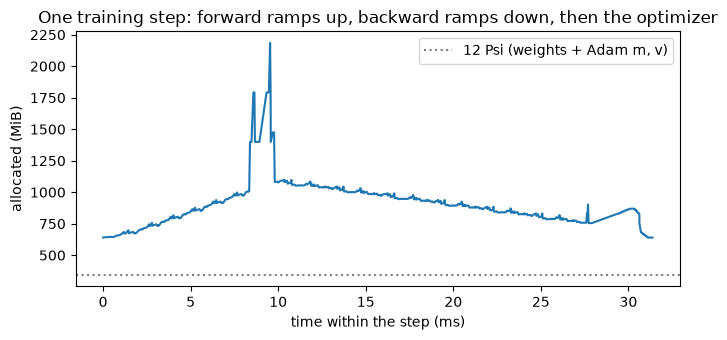

864 alloc/free events; max level 2185 MiB (peak measured above: 2185)


In [12]:
torch.cuda.memory._record_memory_history(max_entries=100_000)
start = torch.cuda.memory_allocated()
train_step(plain)
torch.cuda.synchronize()
snap = torch.cuda.memory._snapshot()
torch.cuda.memory._record_memory_history(enabled=None)
level, ts, ys = start, [], []
for ev in snap["device_traces"][dev.index or 0]:
    if ev["action"] == "alloc":
        level += ev["size"]
    elif ev["action"] == "free_completed":
        level -= ev["size"]
    else:
        continue
    ts.append(ev["time_us"]); ys.append(level)
ts = (np.array(ts) - ts[0]) / 1e3
plt.figure(figsize=(7, 3.5))
plt.plot(ts, np.array(ys) / 2**20)
plt.axhline(12 * P / 2**20, color="gray", ls=":", label="12 Psi (weights + Adam m, v)")
plt.xlabel("time within the step (ms)"); plt.ylabel("allocated (MiB)")
plt.title("One training step: forward ramps up, backward ramps down, then the optimizer"); plt.legend(); plt.tight_layout(); plt.show()
print(f"{len(ys)} alloc/free events; max level {max(ys) / 2**20:.0f} MiB (peak measured above: {(peak + base0) / 2**20:.0f})")

## 5. Activation checkpointing

`torch.utils.checkpoint.checkpoint(fn, x, use_reentrant=False)` runs `fn` without saving its intermediates, keeps
only its input, and re-runs `fn` during the backward to rebuild them. Checkpointing every block of an $L$-block model
stores $L$ block inputs ($sbh$ each) instead of $L$ blocks' activations; at any moment of the backward one block's
activations are live again. Cost: one extra forward of the checkpointed part, about $+33\%$ of its
forward+backward FLOPs (forward : backward ≈ 1 : 2, G1.3). In tinygpt the LM head (not checkpointed) is about 2/3 of
all FLOPs, so expect a smaller overhead on the whole step. Checkpointing every $\sqrt L$ blocks gives
$O(\sqrt L)$ memory (Chen et al. 2016); **selective** recomputation (Korthikanti et al. 2022) recomputes only the
cheap-to-recompute, memory-hungry softmax part, which is what FlashAttention does implicitly.

**Exercise 5.1.** `forward_ckpt(model, idx, targets)` must return the same loss as `model(idx, targets)[1]` but wrap
each block in `checkpoint(..., use_reentrant=False)`. (Re-implement `GPT.forward`; read `prep/tinygpt.py`.)
**Predict** the activation memory after the forward, then check.

In [13]:
def forward_ckpt(model, idx, targets):
    T = idx.shape[1]
    x = model.tok_emb(idx) + model.pos_emb(torch.arange(T, device=idx.device))
    for blk in model.blocks:
        x = checkpoint(blk, x, use_reentrant=False)
    logits = model.head(model.ln_f(x))
    return F.cross_entropy(logits.flatten(0, 1), targets.flatten())


# correctness: same loss and same gradients as the plain forward
torch.manual_seed(0)
ref_model = GPT(cfg_n).to(dev)
ref_loss = ref_model(xb, yb)[1]
ref_loss.backward()
ref_grads = [p.grad.clone() for p in ref_model.parameters()]
ref_model.zero_grad(set_to_none=True)
ck_loss = forward_ckpt(ref_model, xb, yb)
ck_loss.backward()
check_close("checkpointed loss", ck_loss, ref_loss, rtol=1e-6, atol=1e-6)
check("checkpointed gradients", all(torch.allclose(p.grad, g, rtol=1e-4, atol=1e-6) for p, g in zip(ref_model.parameters(), ref_grads)))
del ref_model, ref_grads, ref_loss, ck_loss


def time_steps(forward, n=8):
    for _ in range(2):
        train_step(forward)
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(n):
        train_step(forward)
    torch.cuda.synchronize()
    return (time.perf_counter() - t0) / n


ckpt = lambda: forward_ckpt(model, xb, yb)
results = {}
for name, fwd in (("plain", plain), ("checkpoint every block", ckpt)):
    train_step(fwd)
    torch.cuda.reset_peak_memory_stats()
    a = train_step(fwd)
    results[name] = (a, torch.cuda.max_memory_allocated() - base0, time_steps(fwd))
    print(f"{name:24s} activations {a / 2**20:7.1f} MiB   peak {results[name][1] / 2**20:7.1f} MiB   "
          f"step {results[name][2] * 1e3:6.1f} ms")
sbh = 8 * cfg_n.context_length * cfg_n.d_model
pred_ck = act_pred - 4 * cfg_n.n_layers * (16 * sbh + cfg_n.n_heads * cfg_n.context_length**2 * 8) + 4 * cfg_n.n_layers * sbh
check_close("checkpointed activations = block inputs + head terms", results["checkpoint every block"][0], pred_ck, rtol=0.03, atol=0)
slow = results["checkpoint every block"][2] / results["plain"][2]
print(f"recompute overhead: {slow:.2f}x step time")
check("checkpointing costs extra time but less than 2x", 1.03 < slow < 2.0)

ok  checkpointed loss
ok  checkpointed gradients


plain                    activations   760.0 MiB   peak  1892.3 MiB   step   31.8 ms


checkpoint every block   activations   417.4 MiB   peak  1549.8 MiB   step   37.9 ms
ok  checkpointed activations = block inputs + head terms
recompute overhead: 1.19x step time
ok  checkpointing costs extra time but less than 2x


## 6. The interview estimate: memory to train a 7B model

**Exercise 6.1.** For a Llama-2-7B-shaped model ($\Psi = 7\times10^9$, $L=32$, $h=4096$, $a=32$, $s=4096$, micro-batch
$b=1$) trained with AdamW in mixed precision, return (in bytes): model states; activations with the Megatron formula
and no recomputation; activations when FlashAttention removes the $5as/h$ term; activations with full
recomputation (only each layer's 16-bit input, $2sbhL$). Then answer in words: does it fit on one 80 GB GPU? On eight?

In [14]:
def estimate_7b():
    Psi, L, h, a, s_, b = 7e9, 32, 4096, 32, 4096, 1
    return dict(states=model_state_bytes(Psi, "mixed_adam"),
                act_no_recompute=L * megatron_act_bytes_per_layer(s_, b, h, a),
                act_flash=L * s_ * b * h * 34,
                act_full_recompute=2 * s_ * b * h * L)


est = estimate_7b()
for k, v in est.items():
    print(f"{k:20s} {v / 1e9:8.1f} GB")
check_close("states = 16 Psi = 112 GB", est["states"], 112e9, rtol=1e-9, atol=0)
check_close("no recompute: 32 * s*h*(34 + 5*a*s/h)", est["act_no_recompute"], 32 * 4096 * 4096 * (34 + 160), rtol=1e-9, atol=0)
check_close("FlashAttention removes the s^2 term", est["act_flash"], 32 * 4096 * 4096 * 34, rtol=1e-9, atol=0)
check_close("full recompute keeps 2sbh per layer", est["act_full_recompute"], 2 * 4096 * 4096 * 32, rtol=1e-9, atol=0)

states                  112.0 GB
act_no_recompute        104.2 GB
act_flash                18.3 GB
act_full_recompute        1.1 GB
ok  states = 16 Psi = 112 GB
ok  no recompute: 32 * s*h*(34 + 5*a*s/h)
ok  FlashAttention removes the s^2 term
ok  full recompute keeps 2sbh per layer


**Answer.** States alone are 112 GB, more than one 80 GB GPU, before any activation (104 GB more without
recomputation at $s=4096$, 18 GB with FlashAttention, about 1 GB with full recomputation). On 8×80 GB with plain data
parallelism every GPU still holds all 112 GB of states, so it does not fit. With ZeRO-3/FSDP each GPU holds
$112/8 = 14$ GB of states plus its activations (18 GB with FlashAttention at $b=1$, $s=4096$) plus temporary
all-gathered layers and buffers: about 35-40 GB, comfortable. ZeRO-2 (shard grads + optimizer, replicate 2-byte weights):
$14 + 98/8 \approx 26$ GB of states. Also budget the logits ($sbV$ with $V = 32000$: 0.5 GB in fp32 at $b=1$) and
10-20% allocator fragmentation.

## Say it out loud
1. Derive fp16's max, smallest normal, smallest subnormal and epsilon from its bit layout. Same for bf16. Why is
   E4M3's max 448 and not 240?
2. Why does fp16 training need loss scaling and bf16 training usually not? What does a dynamic loss scaler do on an
   overflow, and why is skipping that step safe?
3. Under `torch.autocast(dtype=torch.float16)`, what dtype are the parameters, a linear layer's output, LayerNorm's
   output, the loss, and the gradients? Why does LayerNorm run in fp32?
4. Mixed-precision Adam costs 16 bytes per parameter. Itemize them. Why doesn't mixed precision reduce this?
5. Write down the per-layer activation memory of a transformer and its assumptions. Which term does FlashAttention
   remove? What does sequence parallelism or tensor parallelism divide?
6. You checkpoint every block of a 32-layer model. What is the new activation memory and the compute overhead? How
   would you get $O(\sqrt L)$? What is selective recomputation?
7. Estimate the memory to train a 7B model with AdamW at $s=4096$. How many 80 GB GPUs, with which sharding?
8. Your training run OOMs only at step 2, not step 1. Why might that be?

<details><summary>Model answers</summary>

1. fp16: $e=5,m=10$, bias 15. Max $(2-2^{-10})\cdot 2^{15} = 65504$; smallest normal $2^{-14}\approx 6.1\times10^{-5}$;
   smallest subnormal $2^{-24}\approx 6\times 10^{-8}$; eps $2^{-10}$. bf16: $e=8,m=7$, bias 127: max $\approx 3.39\times10^{38}$,
   smallest normal $2^{-126}$, eps $2^{-7}$ (`torch.finfo` reports eps; "resolution" is a decimal digits notion).
   E4M3fn reclaims the all-ones exponent for normal numbers (no infinities, only S.1111.111 is NaN), so its max is
   $1.75\times2^{8} = 448$; an IEEE-style E4M3 would stop at $1.875\times 2^7 = 240$ (Micikevicius et al. 2022).
2. fp16's exponent range is narrow: gradients below $2^{-24}$ flush to zero (we measured ~half of tinygpt's gradient
   entries at init) and values above 65504 overflow. Multiplying the loss by $S$ shifts gradients into range; unscale in
   fp32 before clipping/stepping. bf16 has fp32's 8-bit exponent, so nothing underflows that fp32 would represent.
   On inf/NaN, halve $S$ and skip the update; the weights are unchanged and the next step retries, so you only lose one
   batch. After `growth_interval` good steps, double $S$ to use the range again.
3. Parameters fp32 (autocast casts on the fly and caches the casts); linear output fp16; LayerNorm output fp32;
   loss fp32; gradients fp32 (CS336 A2 §2.1.5). LayerNorm computes a mean and variance (reductions over $h$) and divides by
   $\sqrt{\text{var}+\epsilon}$; in fp16 the sum of squares can overflow and the variance loses precision, so autocast
   lists it as an fp32 op. With bf16 overflow is not an issue but precision still argues for fp32 reductions.
4. 2 (fp16/bf16 weights) + 2 (fp16/bf16 grads) + 4 (fp32 master weights) + 4 (Adam $m$) + 4 (Adam $v$) = 16 (ZeRO §3.1).
   The optimizer needs fp32 to apply small updates without rounding them away, so the 16-bit copies are *in addition*
   to fp32 state. PyTorch AMP instead keeps fp32 weights and grads: also 16. Mixed precision saves activation memory
   and time, not state memory.
5. $sbh(34 + 5as/h)$ bytes per layer (Korthikanti et al. 2022, Eq. 1): 16-bit activations, 1-byte dropout masks, MLP
   width $4h$, LayerNorm stats ignored, no parallelism, no recomputation. FlashAttention removes the $5as^2b$ term
   (softmax output, its dropout mask and output), leaving $34\,sbh$ plus an $O(sb\,a)$ logsumexp. Tensor parallelism of
   degree $t$ divides most terms by $t$ ($10 + 24/t + 5as/(ht)$); sequence parallelism also splits the remaining
   $10\,sbh$ (LayerNorm and dropout regions) across the $t$ ranks: $sbh(34 + 5as/h)/t$.
6. Stored: $L$ inputs of $2sbh$ bytes (16-bit) $= 2sbhL$, plus one block's full activations live during its recompute.
   Compute: one extra forward, so about $4/3$ of the FLOPs of forward+backward (we measured the step-time ratio above).
   $O(\sqrt L)$: checkpoint segments of $\sqrt L$ blocks; memory $\sqrt L$ segment inputs + one segment's activations
   (Chen et al. 2016). Selective: keep the cheap-to-store, expensive-to-recompute matmul outputs and recompute only the
   attention softmax/dropout part, which is large but costs few FLOPs (Korthikanti et al. 2022).
7. 112 GB states + 18-104 GB activations (with/without FlashAttention) at $b=1$: never on one 80 GB GPU. With ZeRO-3/FSDP on
   8 GPUs: 14 GB states per GPU + activations + gathered-layer buffers, roughly 35-40 GB each with FlashAttention.
8. Adam's $m$ and $v$ ($8\Psi$ bytes in fp32) are allocated lazily at the first `optimizer.step()`, so step 1's forward and
   backward run without them. Also, if gradients are zeroed with `set_to_none=False` they stay allocated through the
   next forward, and the caching allocator's fragmentation can grow.
</details>

In [15]:
s.finish(lookups=0, score=None, notes="")

[G1.2] done in 0.3 min (within target 120 min)


0.26314008235931396